In [ ]:
# Import modules
import os
import sys

# Make sure that the executable path exists in the environment path
env_bin = os.path.dirname(sys.executable)
if env_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{env_bin}:{os.environ['PATH']}"

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cm
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import scipy.signal as signal
import xarray as xr
import yaml

with open("config.yml") as f:
    config = yaml.safe_load(f)
viz_opts = config["viz"]

In [2]:
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=4, threads_per_worker=4)
client = Client(cluster)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 16,Total memory: 8.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:45831,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:33823,Total threads: 4
Dashboard: http://127.0.0.1:42053/status,Memory: 2.00 GiB
Nanny: tcp://127.0.0.1:38311,


# Define Helper Functions

In [7]:
def setup_Weddell_Sea(fig):

    # Define the projection for a high-resolution South Polar Stereographic map
    high_res_proj = ccrs.SouthPolarStereo(central_longitude=-50)
    high_res_proj.threshold = 1e3

    ax = fig.add_subplot(111, projection=high_res_proj)
    ax.add_feature(cfeature.LAND, color="grey")

    # Define the limits for the x-axis and y-axis of the map
    xlim = [-80, -20]  # longitude
    ylim = [-60, -80]  # latitude

    # Define a rectangular path for the map extent using matplotlib's Path object
    rect = mpath.Path(
        [
            [xlim[0], ylim[0]],
            [xlim[1], ylim[0]],
            [xlim[1], ylim[1]],
            [xlim[0], ylim[1]],
            [xlim[0], ylim[0]],
        ]
    )

    # Transform the rectangular path to the data coordinate system
    proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
    rect_in_target = proj_to_data.transform_path(rect)

    # Set the boundary of the map using the transformed rectangular path
    ax.set_boundary(rect_in_target)

    # Configure gridlines for the map
    gl = ax.gridlines(draw_labels=["top", "right", "x", "y"], rotate_labels=True, x_inline=False)

    # Draw latitude and longitude gridlines (and their labels)
    # only at the specified values
    lathelp = np.arange(-75, -60, 5)
    gl.ylocator = mticker.FixedLocator(lathelp)
    lonhelp = np.arange(-80, -10, 10)
    gl.xlocator = mticker.FixedLocator(lonhelp)

    # Rotate the longitude labels to be more readable
    gl.xlabel_style = {"rotation": 30}

    # To make sure that all of the wanted map extent is visible in the figure,
    # (especially because the chosen map projections differs strongly
    # at the poles from the PlateCarree Projection)
    # this hack of adding a constant is needed and may need be adjusted,
    # dependent on your map extent and figure size
    ax.set_extent([xlim[0], xlim[1], ylim[0] + 4, ylim[1]])

    return ax

# Load ERA5 Data

In [8]:
# wind = xr.open_dataset("./data/era5_winddata.grib", engine="cfgrib", chunks='auto')
wind = xr.open_dataset(
    "./data/era5_2022_2023.grib",
    engine="cfgrib",
    chunks={"time": 1000, "latitude": 200, "longitude": 200},
)

In [9]:
wind

<xarray.Dataset> Size: 3GB
Dimensions:        (time: 8760, latitude: 141, longitude: 321)
Coordinates:
  * time           (time) datetime64[ns] 70kB 2022-01-01 ... 2023-12-31T22:00:00
    valid_time     (time) datetime64[ns] 70kB dask.array<chunksize=(1000,), meta=np.ndarray>
  * latitude       (latitude) float64 1kB -55.0 -55.25 -55.5 ... -89.75 -90.0
  * longitude      (longitude) float64 3kB -80.0 -79.75 -79.5 ... -0.5 -0.25 0.0
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
Data variables:
    u              (time, latitude, longitude) float32 2GB dask.array<chunksize=(1000, 141, 200), meta=np.ndarray>
    v              (time, latitude, longitude) float32 2GB dask.array<chunksize=(1000, 141, 200), meta=np.ndarray>
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-05-15T17:15 GRIB to CDM+CF via cfgrib-0.9.1...

In [18]:
wind["isobaricInhPa"]

<xarray.DataArray 'isobaricInhPa' ()> Size: 8B
[1 values with dtype=float64]
Coordinates:
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
Attributes:
    long_name:         pressure
    units:             hPa
    positive:          down
    stored_direction:  decreasing
    standard_name:     air_pressure


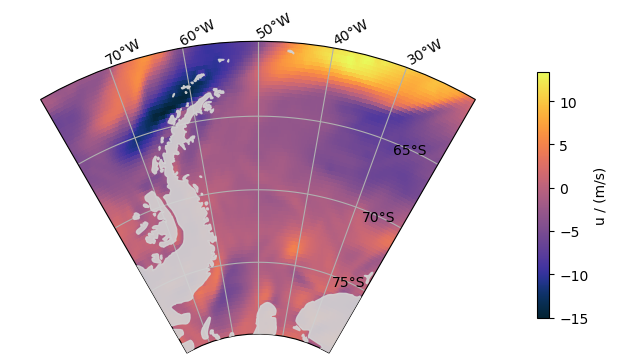

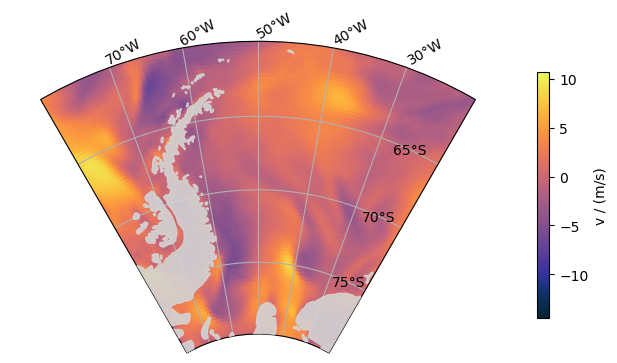

In [10]:
lat = wind.variables["latitude"][:]  # latitude grid points
lon = wind.variables["longitude"][:]  # longitude grid points

fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    lon, lat, wind.isel(time=0).variables["u"], transform=ccrs.PlateCarree(), cmap=cm.cm.thermal
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4, label="u / (m/s)")
fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    lon, lat, wind.isel(time=0).variables["v"], transform=ccrs.PlateCarree(), cmap=cm.cm.thermal
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4, label="v / (m/s)");

# Extract time series at mooring sites

In [22]:
# boxlats = np.array([mooring.location.lat+height_in_lat/2,mooring.location.lat-height_in_lat/2])
# boxlons = np.array([mooring.location.lon-width_in_lon/2,mooring.location.lon+width_in_lon/2])

moorings = {
    "A": {"lat": -63.4032, "lon": -52.287},
    "B": {"lat": -63.5145, "lon": -51.6357},
    "C": {"lat": -63.656, "lon": -50.8113},
    "D": {"lat": -63.7783, "lon": -50.0897},
    "E": {"lat": -63.917, "lon": -49.2682},
    "F": {"lat": -64.0665, "lon": -48.3805},
    "G": {"lat": -64.2157, "lon": -47.4903},
}

mooring_names = moorings.keys()
width_in_lon = 1
height_in_lat = 0.5

# mooring_boxes = {}
# for name, mooring in zip(mooring_names, moorings):

#     boxlats = np.array([mooring.location.lat+height_in_lat/2,mooring.location.lat-height_in_lat/2])
#     boxlons = np.array([mooring.location.lon-width_in_lon/2,mooring.location.lon+width_in_lon/2])

#     mooring_bins[name] = {
#         "lat": boxlats,
#         "lon": boxlons
# }

mooring_boxes = {
    "A": {"lat": np.array([-63.1532, -63.6532]), "lon": np.array([-52.787, -51.787])},
    "B": {"lat": np.array([-63.2645, -63.7645]), "lon": np.array([-52.1357, -51.1357])},
    "C": {"lat": np.array([-63.406, -63.906]), "lon": np.array([-51.3113, -50.3113])},
    "D": {"lat": np.array([-63.5283, -64.0283]), "lon": np.array([-50.5897, -49.5897])},
    "E": {"lat": np.array([-63.667, -64.167]), "lon": np.array([-49.7682, -48.7682])},
    "F": {"lat": np.array([-63.8165, -64.3165]), "lon": np.array([-48.8805, -47.8805])},
    "G": {"lat": np.array([-63.9657, -64.4657]), "lon": np.array([-47.9903, -46.9903])},
}

In [8]:
# for name, bounds in mooring_boxes.items():
#     print(name, bounds)

In [23]:
def setup_transect_view(fig):
    ax = fig.add_subplot(111, projection=ccrs.SouthPolarStereo(central_longitude=-50))
    # Limit the map to -60 degrees latitude and below.
    ax.set_extent([-54, -46, -64.5, -62.6], crs=ccrs.PlateCarree())
    # ax.set_extent([-55, -45, -65, -62], ccrs.PlateCarree())
    ax.gridlines(draw_labels=True)
    return ax

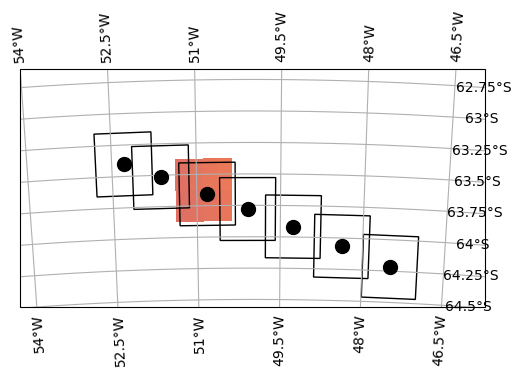

In [ ]:
fig = plt.figure(figsize=(6, 6))
ax = setup_transect_view(fig)

ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)

name = "C"
bounds = mooring_boxes[name]

wind_at_mooring = wind.sel(
    latitude=slice(bounds["lat"][0], bounds["lat"][1]),
    longitude=slice(bounds["lon"][0], bounds["lon"][1]),
)
boxlat = wind_at_mooring.variables["latitude"][:]  # latitude grid points
boxlon = wind_at_mooring.variables["longitude"][:]  # longitude grid points

assert boxlat.size != 1
assert boxlon.size != 1

# Compute monthly statistics averaged over space
im = ax.pcolormesh(
    boxlon,
    boxlat,
    wind_at_mooring.isel(time=0).variables["v"],
    vmin=-6,
    vmax=8,
    transform=ccrs.PlateCarree(),
    cmap=cm.cm.thermal,
    shading="nearest",
)

for name, mooring in moorings.items():
    ax.plot(mooring["lon"], mooring["lat"], "k.", ms=20, transform=ccrs.PlateCarree(), label=name)

for box in mooring_boxes.values():
    patch = mpatches.Rectangle(
        xy=[box["lon"][0], box["lat"][1]],  # lower left corner
        width=width_in_lon,
        height=height_in_lat,
        facecolor="none",
        edgecolor="k",
        transform=ccrs.PlateCarree(),
    )
    # assert np.all(patch.get_center() == (mooring["lon"], mooring["lat"]))
    ax.add_patch(patch)

In [25]:
# Create an empty dictionary to store results
results = {}
for name, bounds in mooring_boxes.items():
    wind_at_mooring = wind.sel(
        latitude=slice(bounds["lat"][0], bounds["lat"][1]),
        longitude=slice(bounds["lon"][0], bounds["lon"][1]),
    )

    # complex_wind = wind_at_mooring.assign(wind = wind_at_mooring.u + 1j * wind_at_mooring.v)
    # Compute monthly statistics averaged over space
    wind_mean = (wind_at_mooring.mean(dim=["latitude", "longitude"])).chunk({"time": 1000})
    wind_std = (wind_at_mooring.std(dim=["latitude", "longitude"])).chunk({"time": 1000})

    results[name] = {"mean": wind_mean, "std": wind_std}

In [31]:
results["C"]["mean"]["u"]  # .data.dask.visualize(**viz_opts)

<xarray.DataArray 'u' (time: 8760)> Size: 35kB
dask.array<mean_agg-aggregate, shape=(8760,), dtype=float32, chunksize=(1000,), chunktype=numpy.ndarray>
Coordinates:
  * time           (time) datetime64[ns] 70kB 2022-01-01 ... 2023-12-31T22:00:00
    valid_time     (time) datetime64[ns] 70kB dask.array<chunksize=(1000,), meta=np.ndarray>
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
Attributes: (12/31)
    GRIB_paramId:                             131
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      45261
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:                           u
    GRIB_totalNumber:                         0
    GRIB_units:                               m s**-1
    long_name:                                U component of wind
    units:                                    m s**-1
    standard_name:                            eastward_wind

In [32]:
mean_wind_df = pd.DataFrame(index=wind_mean["time"])
std_wind_df = pd.DataFrame(index=wind_std.variables["time"].values)
for name, result in results.items():
    mean_wind_df[name] = (result["mean"].variables["u"] + 1j * result["mean"].variables["v"]).load()
    std_wind_df[name] = (result["std"].variables["u"] + 1j * result["std"].variables["v"]).load()

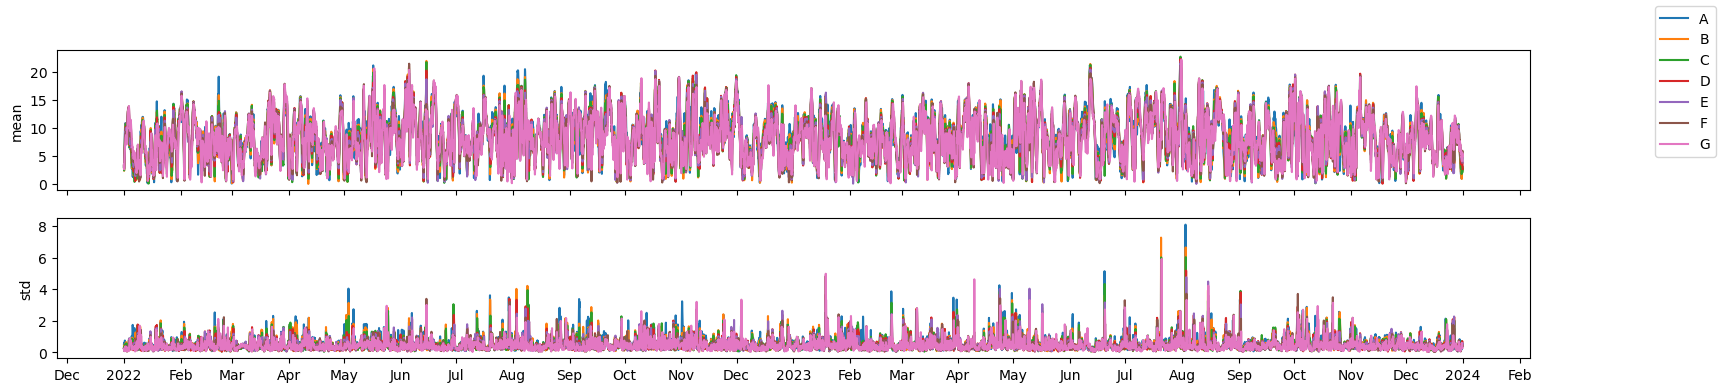

In [33]:
fig, ax = plt.subplots(nrows=2, figsize=(19, 4), sharex=True)
for col in mean_wind_df.columns:
    ax[0].plot(mean_wind_df.index, mean_wind_df[col].abs(), label=col)
    ax[1].plot(std_wind_df.index, std_wind_df[col].abs())  # , label = col)
fig.legend()
ax[0].set_ylabel("mean")
ax[1].set_ylabel("std")
locator = mdates.AutoDateLocator(minticks=5, maxticks=50)
formatter = mdates.ConciseDateFormatter(locator)
ax[1].xaxis.set_major_locator(locator)
ax[1].xaxis.set_major_formatter(formatter)

In [35]:
mean_wind_df

,A,B,C,D,E,F,G
2022-01-01 00:00:00,-2.220886+2.129776j,-1.149231+2.584976j,-0.646545+3.022964j,-0.964661+3.109634j,-1.314270+3.061050j,-2.023499+2.589371j,-2.580872+2.293350j
2022-01-01 02:00:00,-2.901840+0.979950j,-1.715073+1.649017j,-1.362534+2.019989j,-1.656967+2.198456j,-1.892563+2.064301j,-2.213608+1.584442j,-2.350815+1.221161j
2022-01-01 04:00:00,-4.546982+0.982315j,-3.288681+1.503067j,-2.880600+1.602921j,-3.030746+1.527481j,-3.171616+1.299210j,-3.129135+0.941055j,-2.896591+0.725357j
2022-01-01 06:00:00,-6.030258-0.436203j,-4.867783+0.271683j,-4.381943+0.088455j,-4.106186-0.197067j,-4.130844-0.352097j,-4.185287-0.064743j,-4.047958+0.006546j
2022-01-01 08:00:00,-7.127945-1.364365j,-5.858414-0.806747j,-5.389542-1.035873j,-4.964493-1.018906j,-4.778091-1.266708j,-4.510635-1.534286j,-4.361588-1.681259j
...,...,...,...,...,...,...,...
2023-12-31 14:00:00,1.597427-1.305222j,1.658951-0.541550j,2.094986+0.759842j,2.487198+2.257889j,2.027359+3.484329j,1.399063+3.749222j,-0.219589+4.069778j
2023-12-31 16:00:00,2.155304-1.632111j,2.102203-0.657013j,2.350372+0.638275j,3.149200+2.067230j,3.287140+3.348602j,2.277618+3.951019j,0.759308+4.054291j
2023-12-31 18:00:00,2.866180-1.539764j,2.716278-0.513641j,2.687958+0.767853j,3.340424+2.089630j,3.885956+3.688019j,3.135468+4.731598j,1.759857+4.527496j
2023-12-31 20:00:00,2.967484-1.265152j,3.063065-0.340225j,2.787308+0.904648j,3.002274+2.088486j,3.450150+3.676010j,3.109940+5.051743j,2.136307+5.020737j


# Filter to wind at inertial frequencies

In [36]:
def get_coriolis_frequency(lat, unit="rad/s", absolute=False):

    if absolute:
        lat = abs(lat)

    Omega = 7.2921 * 1e-5  # unit: rad/s

    f = 2 * Omega * np.sin(lat * np.pi / 180.0)

    if unit == "rad/s":
        return f

    if unit == "Hz":
        return f / (2 * np.pi)

    if unit == "cpd":
        return f / (2 * np.pi) * 3600 * 24

    raise NotImplementedError("Specified unit is not implemented")

In [37]:
def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    """
    # Sample rate and desired cutoff frequencies (in Hz).
    fs = 1/7200 #sampling period of 2 hours
    lowcut = 1/(14*60*60) #period of 18 hours
    highcut = 1/(10*60*60) #period of 10 hours
    filtered_u = butter_bandpass_filter(patched_u, lowcut, highcut, fs, order=6)
    filtered_v = butter_bandpass_filter(patched_v, lowcut, highcut, fs, order=6)
    """
    # from scipy.signal import lfilter
    # b, a = Data.butter_bandpass(lowcut, highcut, fs, order=order)
    # y = lfilter(b, a, data)

    # use of second-order sections (sos) as recommended in https://docs.scipy.org/doc/scipy-1.14.1/reference/generated/scipy.signal.butter.html
    sos = signal.butter(order, [lowcut, highcut], "bandpass", fs=fs, output="sos")
    # use filtfilt with 2 filtering passes to prevent an artificial phase shift
    filtered = signal.sosfiltfilt(sos, data)

    return filtered

In [38]:
mean_wind_around_f = pd.DataFrame(index=mean_wind_df.index)

mean_lat = -64
f_in_Hz = get_coriolis_frequency(lat=mean_lat, unit="Hz", absolute=True)
f_in_cpd = get_coriolis_frequency(lat=mean_lat, unit="cpd", absolute=True)
print(f_in_Hz, f_in_cpd)

2.08623357249356e-05 1.8025058066344357


In [39]:
lowcut = f_in_Hz * 0.9
highcut = f_in_Hz * 1.1
two_hour_period = 1 / 7200
for name, series in mean_wind_df.items():
    mean_wind_around_f[name] = butter_bandpass_filter(
        series, lowcut, highcut, fs=two_hour_period, order=5
    )

In [40]:
mean_wind_around_f

,A,B,C,D,E,F,G
2022-01-01 00:00:00,-0.025961-0.041349j,-0.028923-0.050321j,-0.007281-0.017239j,0.013400+0.007735j,0.017976+0.016395j,0.003397+0.007255j,-0.008191-0.005468j
2022-01-01 02:00:00,0.353471-0.424700j,0.230079-0.318031j,0.219972-0.162564j,0.106029-0.124132j,0.110819-0.163877j,0.175892-0.227085j,0.281723-0.279997j
2022-01-01 04:00:00,0.455551-0.432517j,0.310566-0.301441j,0.272507-0.146985j,0.117493-0.129768j,0.121919-0.183057j,0.222535-0.249788j,0.365046-0.294383j
2022-01-01 06:00:00,0.198479-0.057718j,0.147545-0.013925j,0.108214+0.016060j,0.042890-0.004858j,0.047369-0.025111j,0.109328-0.044483j,0.176019-0.038674j
2022-01-01 08:00:00,-0.214804+0.369033j,-0.132644+0.288664j,-0.142283+0.170167j,-0.061461+0.128347j,-0.059547+0.158558j,-0.085774+0.199087j,-0.149405+0.251318j
...,...,...,...,...,...,...,...
2023-12-31 14:00:00,-0.010185+0.001479j,-0.035033+0.016827j,-0.055809-0.005371j,-0.088140-0.019611j,-0.031699-0.016591j,0.073060-0.043108j,-0.021925-0.095367j
2023-12-31 16:00:00,-0.031130+0.099800j,-0.065985+0.123747j,-0.092143+0.095104j,-0.086133+0.028505j,-0.031492+0.033735j,0.054236+0.089551j,0.032294+0.028852j
2023-12-31 18:00:00,-0.021612+0.109415j,-0.037531+0.122573j,-0.046618+0.110628j,-0.007367+0.050876j,0.005261+0.053759j,0.005123+0.136792j,0.060544+0.113769j
2023-12-31 20:00:00,0.003582+0.033500j,0.016281+0.027641j,0.029507+0.040136j,0.068718+0.033866j,0.036978+0.032894j,-0.037444+0.073835j,0.039182+0.098744j


In [41]:
def smooth(array, length):
    window = signal.windows.hann(length)  # construct Hanning window
    # smooth by convolving speed with window
    smoothed = signal.convolve(array, window, mode="same") / np.sum(window)
    return smoothed

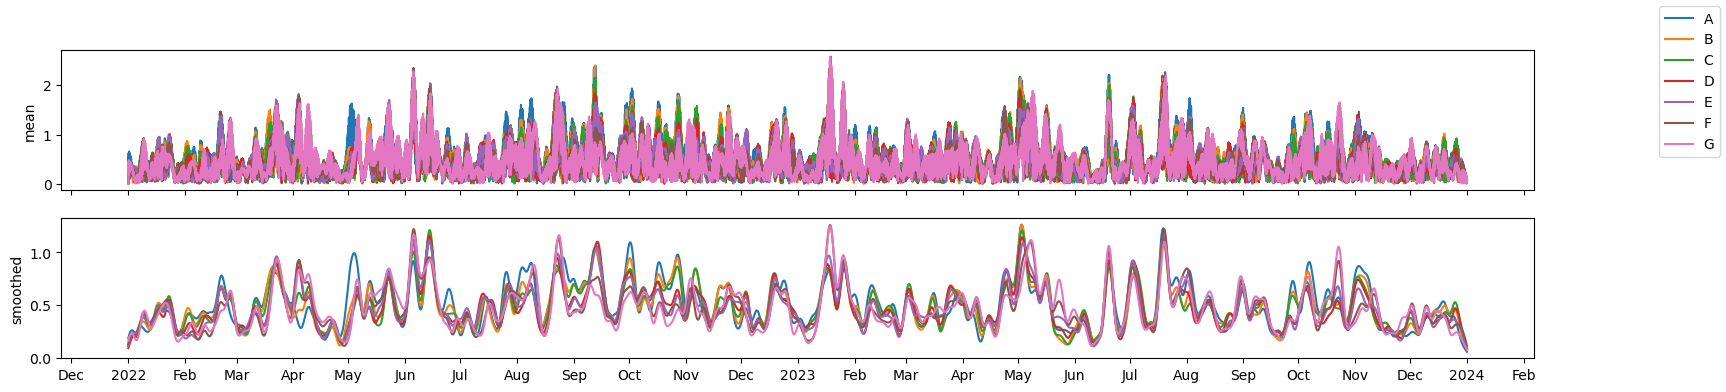

In [42]:
fig, ax = plt.subplots(nrows=2, figsize=(19, 4), sharex=True)
for col in mean_wind_df.columns:
    ax[0].plot(mean_wind_around_f.index, mean_wind_around_f[col].abs(), label=col)
    ax[1].plot(mean_wind_around_f.index, smooth(mean_wind_around_f[col].abs(), 100))
fig.legend()
ax[0].set_ylabel("mean")
ax[1].set_ylabel("smoothed")
locator = mdates.AutoDateLocator(minticks=5, maxticks=50)
formatter = mdates.ConciseDateFormatter(locator)
ax[1].xaxis.set_major_locator(locator)
ax[1].xaxis.set_major_formatter(formatter)

In [43]:
mean_wind_around_f.to_csv("./inertial_wind_2022_2023.csv")